# 03 · EGCC: шесть диагностических записей

**Исследовательский вопрос:** Какие факты подтверждены для каждой записи и что может показать условный временной сценарий?

**Входные материалы:** локальный разбор случаев, соседние записи тех же бортов и исходный Parquet

Расчеты ниже выполняются в ячейках. Все исходные строки сохраняются. Округление таблиц используется только для чтения результатов.

In [1]:
# Подключаем библиотеки и находим корень проекта
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
# Подключаем проверенные геодезические функции без запуска скриптов
sys.path.insert(0, str(root/'europe/scripts'))
from audit_c40_radial_cases import ellipsoid_distance, validate_distance
from investigate_c40_geometry import distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})
# Таблицы округляем только при отображении, расчетные значения сохраняем
pd.set_option('display.max_columns', 14)


## 1. Читаем случаи и перепроверяем исходные поля

Порог 1 км выбран для диагностики по WGS84. Сверка с исходником не устанавливает физическую правильность позиции, но исключает изменение этих полей при подготовке.

In [2]:
import pyarrow.parquet as pq
cases = pd.read_csv(study/'reports/03_egcc_case_review.csv')
display(cases[['flight_id','icao24','typecode','GoA','sphere_m','wgs84_m','minutes_to_landing']].round(2))
# Подтягиваем только выбранные поля исходного EGCC
key = ['icao24','airport','landing_time']
fields = key+['flight_id','C40_CROSS_TIME','C40_CROSS_LAT','C40_CROSS_LON','C40_BEARING','n_attempts']
raw = pq.read_table(root/'europe/data/source/osn23_landings_merged.parquet.gzip',
                    columns=fields,filters=[('airport','=','EGCC')]).to_pandas(ignore_metadata=True)
# Приводим только представление времени для сопоставления ключей
for col in ['landing_time','C40_CROSS_TIME']:
    raw[col] = pd.to_datetime(raw[col],utc=True)
    cases[col] = pd.to_datetime(cases[col],utc=True)
merged = cases.merge(raw,on=key,suffixes=('_review','_source'),validate='one_to_one')
for field in [f for f in fields if f not in key]:
    assert merged[field+'_review'].eq(merged[field+'_source']).all(), field
display(Markdown(f'**Сверено с исходником: {len(merged)} записей**'))

,flight_id,icao24,typecode,GoA,sphere_m,wgs84_m,minutes_to_landing
0,TOM24E_20390,40647f,B738,False,869.66,1046.23,11.57
1,DLH948_5982,3c6645,A321,False,1312.63,1548.36,9.10
2,EZY86TC_37562,40756d,A20N,False,1100.00,1343.91,9.48
3,RYR646N_61363,4ca75f,B738,False,816.34,1025.94,6.97
4,TOM137F_28522,406d70,B788,False,888.10,1115.39,21.03
5,SHT2N_3852,4009d8,A320,False,-1256.62,-1065.58,10.45


**Сверено с исходником: 6 записей**

## 2. Проверяем чувствительность к метрике

Пересчитываем радиальные отклонения непосредственно по координатам. Случаи нельзя объявить ошибками или удалить только по диагностическому порогу.

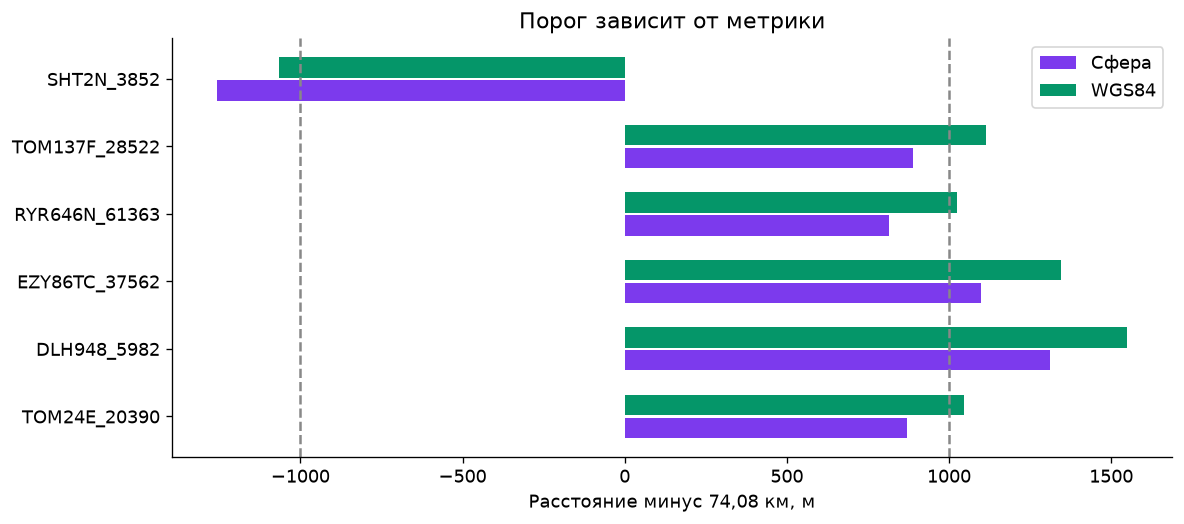

In [3]:
# Используем подтвержденные координаты EGCC
lat, lon = cases.C40_CROSS_LAT.to_numpy(), cases.C40_CROSS_LON.to_numpy()
sphere = 1000*(distance(53.35388888888889,-2.275,lat,lon)-74.08)
wgs84 = 1000*(ellipsoid_distance(53.35388888888889,-2.275,lat,lon)-74.08)
assert np.allclose(sphere,cases.sphere_m) and np.allclose(wgs84,cases.wgs84_m)
# Сравниваем отклонения на одной шкале
fig, ax = plt.subplots(figsize=(10,4.5))
y = np.arange(len(cases))
ax.barh(y-.17,sphere,height=.3,label='Сфера',color='#7C3AED')
ax.barh(y+.17,wgs84,height=.3,label='WGS84',color='#059669')
for value in [-1000,1000]:
    ax.axvline(value,color='#888',linestyle='--')
ax.set(yticks=y,yticklabels=cases.flight_id,xlabel='Расстояние минус 74,08 км, м',title='Порог зависит от метрики')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Считаем условный временной сдвиг

Формула Δt = |отклонение| / предполагаемая радиальная скорость проверяет совместимость сценария. Скорости 50–150 м/с не измерены; частота исходных CPR неизвестна.

In [4]:
# Создаем сценарии явно, не выдавая скорости за наблюдения
rows = []
for case in cases.itertuples():
    for model, residual in [('sphere',case.sphere_m),('wgs84',case.wgs84_m)]:
        for speed in [50.,100.,150.]:
            rows.append({'flight_id':case.flight_id,'model':model,'radial_speed_m_s':speed,
                         'hypothetical_seconds':abs(residual)/speed})
scenarios = pd.DataFrame(rows)
display(scenarios.pivot(index=['flight_id','model'],columns='radial_speed_m_s',values='hypothetical_seconds').round(2))
# Сверяем сценарии с прежним отчетом по всем ключам
saved = pd.read_csv(study/'reports/03_egcc_sampling_scenarios.csv')
check = scenarios.merge(saved,on=['flight_id','model','radial_speed_m_s'],suffixes=('_new','_saved'),validate='one_to_one')
assert np.allclose(check.hypothetical_seconds_new,check.hypothetical_seconds_saved)
# Контекст соседних записей не считается независимой контрольной группой
display(cases[['flight_id','point_rows','same_board_other_rows_30d','sector_other_rows','n_attempts']])

radial_speed_m_s      50.0   100.0  150.0
flight_id     model                      
DLH948_5982   sphere  26.25  13.13   8.75
              wgs84   30.97  15.48  10.32
EZY86TC_37562 sphere  22.00  11.00   7.33
              wgs84   26.88  13.44   8.96
RYR646N_61363 sphere  16.33   8.16   5.44
              wgs84   20.52  10.26   6.84
SHT2N_3852    sphere  25.13  12.57   8.38
              wgs84   21.31  10.66   7.10
TOM137F_28522 sphere  17.76   8.88   5.92
              wgs84   22.31  11.15   7.44
TOM24E_20390  sphere  17.39   8.70   5.80
              wgs84   20.92  10.46   6.97

,flight_id,point_rows,same_board_other_rows_30d,sector_other_rows,n_attempts
0,TOM24E_20390,1,8,12073,1
1,DLH948_5982,1,1,77,1
2,EZY86TC_37562,1,80,978,1
3,RYR646N_61363,1,21,1135,1
4,TOM137F_28522,1,24,8134,1
5,SHT2N_3852,1,2,657,1


## Что установлено и что остается открытым

Поля всех шести случаев сверены с исходником. Условный временной сценарий не доказывает частоту наблюдений или причину отклонения. Все строки сохраняются; для механизма нужна последовательность наблюдений.

## Методические подробности и происхождение источников

# Конкретные радиальные случаи EGCC

Источник и локальный контекст каждой записи. Все строки сохраняются.

---

## Что проверено

Шесть разных бортов и дат; все записи имеют одну попытку посадки. C40 предшествует попытке. Ключи и выбранные геометрические поля точно совпадают с исходным Parquet. По WGS84 все шесть превышают 1 км; по сфере только три. Следовательно, состав группы по этому диагностическому порогу чувствителен к метрике. Это не правило удаления.

## Что дает временной сценарий

При постоянной локальной радиальной скорости $v_r$:
$$\Delta t\approx |d-r|/|v_r|.$$
Это расчет совместимости гипотезы с величиной отклонения. Скорость и частота CPR в этих записях неизвестны. Радиальная скорость является компонентой путевой скорости относительно ARP и не равна воздушной скорости самолета. Числа 50, 100 и 150 м/с заданы как сценарии, не как измерения или авиационная норма.

При входящем движении точка снаружи границы совместима с наблюдением до пересечения, внутри – после него. Но без траектории направление радиального движения не установлено; по одной точке выбирать механизм нельзя.

Близкие записи того же борта и азимутного сектора – описательный контекст. Это не независимые контрольные группы, а другие наблюдения той же базы. Процентили времени до посадки вычислены среди GoA=False и не оценивают статистическую значимость.

## Решение

Все записи сохранены. Для каждой отдельно фиксируем метрику, отклонение и диагностические признаки. Следующий источник для проверки механизма – последовательность CPR/траектория и алгоритм выбора точки пересечения. Уходов в этой группе нет; она не объясняет всплеск GoA февраля 2020 года.


---

Воспроизведение: `.\.venv\Scripts\python.exe -u -X utf8 research/c40_geometry/scripts/investigate_egcc_cases.py`. Исторические координаты и ссылки – в 01_historical_arp. Геодезические методы – Vincenty (1975), https://www.ngs.noaa.gov/PUBS_LIB/inverse.pdf ; Karney (2013), https://doi.org/10.1007/s00190-012-0578-z . Формула временного сценария – наша локальная кинематическая оценка, не результат этих статей.